# 04 — Generation 1 Formulation Selection

## Objective
Select the first generation of β-glucan nanoparticle formulations directly from `Dataset.xlsx`, preserving the original formulation IDs and experimental column names.

## Main Tasks
1. Load the candidate formulations from the **Nanoparticle Formulation Table** worksheet.
2. Include five mandatory formulations under fixed conditions.
3. Randomly select 15 additional formulations with predefined glucan/modification quotas.
4. Review the selected formulations and save the results for reproducibility.

**Note:** Generation 1 is an initial experimental design; MFI data and a trained Bayesian optimization model are not required.


In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)


# 1. Configuration

Define the first-generation size, category quotas, and random seed.


In [5]:
SEED = 42
GENERATION = 1
N_RECOMMENDED = 15
QUOTAS = {("YG", "SA"): 12, ("BG", "SA"): 1,
          ("C", "SA"): 1, ("YG", "HO"): 1}
assert sum(QUOTAS.values()) == N_RECOMMENDED

XLSX_PATHS = [Path("../data/raw/Dataset.xlsx")]
SHEET_NAME = "Nanoparticle Formulation Table"
OUTPUT_ROOT = Path("../results")  # results/ is a sibling of notebooks/


# 2. Load Candidate Formulations

Read formulation IDs and original experimental columns directly from `Dataset.xlsx`. Blank nanoparticles are excluded from the Generation 1 selection pool.


In [6]:
xlsx_path = next((p for p in XLSX_PATHS if p.exists()), None)
if xlsx_path is None:
    raise FileNotFoundError("Dataset.xlsx not found.")

excel = pd.read_excel(xlsx_path, sheet_name=SHEET_NAME)
assert "ID" in excel.columns, "Missing ID column in Dataset.xlsx"
assert excel["ID"].notna().all(), "Missing formulation IDs"
assert excel["ID"].is_unique, "Duplicate formulation IDs"

pattern = re.compile(
    r"^(YG|BG|C)-(SA|HO)-(D[1-5])-(N[1-6])-"
    r"(R90-10|R70-30|R50-50)-(MH|MM|ML|MU)-(G01|G08|G20)$"
)
parsed = excel["ID"].astype(str).str.extract(pattern)
parsed.columns = ["Glucan_Code", "Modification_Code", "Carrier_1_Code",
                  "Carrier_2_Code", "Ratio_Code", "MW_Code", "Amount_Code"]
candidates = pd.concat([excel[["ID"]], parsed], axis=1).dropna(subset=["Glucan_Code"]).copy()
assert candidates["ID"].is_unique
print("All Excel IDs:", len(excel))
print("β-glucan candidates:", len(candidates))
print("Excluded blank/other IDs:", len(excel) - len(candidates))
display(candidates.head())


All Excel IDs: 6575
β-glucan candidates: 6480
Excluded blank/other IDs: 95


,ID,Glucan_Code,Modification_Code,Carrier_1_Code,Carrier_2_Code,Ratio_Code,MW_Code,Amount_Code
0,YG-SA-D1-N1-R90-10-MH-G01,YG,SA,D1,N1,R90-10,MH,G01
1,YG-SA-D1-N1-R90-10-MH-G08,YG,SA,D1,N1,R90-10,MH,G08
2,YG-SA-D1-N1-R90-10-MH-G20,YG,SA,D1,N1,R90-10,MH,G20
3,YG-SA-D1-N1-R90-10-MM-G01,YG,SA,D1,N1,R90-10,MM,G01
4,YG-SA-D1-N1-R90-10-MM-G08,YG,SA,D1,N1,R90-10,MM,G08


# 3. Mandatory Formulation Selection

Include the five required carrier pairs under identical conditions.


In [7]:
mandatory_ids = [
    f"YG-SA-D{i}-N{i}-R90-10-MU-G08" for i in range(1, 6)
]
mandatory = candidates[candidates["ID"].isin(mandatory_ids)].copy()
assert len(mandatory) == 5 and set(mandatory["ID"]) == set(mandatory_ids)
mandatory["Selection_Type"] = "Mandatory"
mandatory["_order"] = mandatory["ID"].map({v:i for i,v in enumerate(mandatory_ids)})
mandatory = mandatory.sort_values("_order").drop(columns="_order")
display(mandatory)


,ID,Glucan_Code,Modification_Code,Carrier_1_Code,Carrier_2_Code,Ratio_Code,MW_Code,Amount_Code,Selection_Type
10,YG-SA-D1-N1-R90-10-MU-G08,YG,SA,D1,N1,R90-10,MU,G08,Mandatory
262,YG-SA-D2-N2-R90-10-MU-G08,YG,SA,D2,N2,R90-10,MU,G08,Mandatory
514,YG-SA-D3-N3-R90-10-MU-G08,YG,SA,D3,N3,R90-10,MU,G08,Mandatory
766,YG-SA-D4-N4-R90-10-MU-G08,YG,SA,D4,N4,R90-10,MU,G08,Mandatory
1018,YG-SA-D5-N5-R90-10-MU-G08,YG,SA,D5,N5,R90-10,MU,G08,Mandatory


# 4. Constrained Random Sampling

Select 15 nonmandatory candidates while maintaining the predefined glucan/modification quotas.


In [8]:
remaining = candidates[~candidates["ID"].isin(mandatory_ids)].copy()
rng = np.random.default_rng(SEED)
parts = []
for (glucan, modification), count in QUOTAS.items():
    pool = remaining[
        (remaining["Glucan_Code"] == glucan) &
        (remaining["Modification_Code"] == modification)
    ]
    if len(pool) < count:
        raise ValueError(f"Not enough candidates for {glucan}-{modification}")
    chosen_indices = rng.choice(pool.index.to_numpy(), size=count, replace=False)
    parts.append(pool.loc[chosen_indices].copy())

recommended = pd.concat(parts, ignore_index=True)
recommended["Selection_Type"] = "Recommended"
selected = pd.concat([mandatory, recommended], ignore_index=True)
selected.insert(0, "Generation", GENERATION)
assert len(selected) == 20 and selected["ID"].is_unique
assert set(mandatory_ids).issubset(set(selected["ID"]))
print("Mandatory:", len(mandatory), "Recommended:", len(recommended))
display(selected)


Mandatory: 5 Recommended: 15


,Generation,ID,Glucan_Code,Modification_Code,Carrier_1_Code,Carrier_2_Code,Ratio_Code,MW_Code,Amount_Code,Selection_Type
0,1,YG-SA-D1-N1-R90-10-MU-G08,YG,SA,D1,N1,R90-10,MU,G08,Mandatory
1,1,YG-SA-D2-N2-R90-10-MU-G08,YG,SA,D2,N2,R90-10,MU,G08,Mandatory
2,1,YG-SA-D3-N3-R90-10-MU-G08,YG,SA,D3,N3,R90-10,MU,G08,Mandatory
3,1,YG-SA-D4-N4-R90-10-MU-G08,YG,SA,D4,N4,R90-10,MU,G08,Mandatory
4,1,YG-SA-D5-N5-R90-10-MU-G08,YG,SA,D5,N5,R90-10,MU,G08,Mandatory
5,1,YG-SA-D3-N2-R90-10-MH-G20,YG,SA,D3,N2,R90-10,MH,G20,Recommended
6,1,YG-SA-D1-N3-R70-30-ML-G20,YG,SA,D1,N3,R70-30,ML,G20,Recommended
7,1,YG-SA-D4-N6-R90-10-MH-G01,YG,SA,D4,N6,R90-10,MH,G01,Recommended
8,1,YG-SA-D3-N4-R50-50-MM-G08,YG,SA,D3,N4,R50-50,MM,G08,Recommended
9,1,YG-SA-D4-N2-R70-30-MM-G08,YG,SA,D4,N2,R70-30,MM,G08,Recommended


# 5. Selection Quality Assessment

Inspect how Generation 1 covers the main formulation variables.



Glucan_Code


,Count
Glucan_Code,
YG,18
BG,1
C,1



Modification_Code


,Count
Modification_Code,
SA,19
HO,1



Carrier_1_Code


,Count
Carrier_1_Code,
D4,6
D1,4
D3,4
D5,4
D2,2


... (4 outputs left out)


MW_Code


,Count
MW_Code,
MU,9
MM,5
MH,3
ML,3



Amount_Code


,Count
Amount_Code,
G08,9
G20,6
G01,5


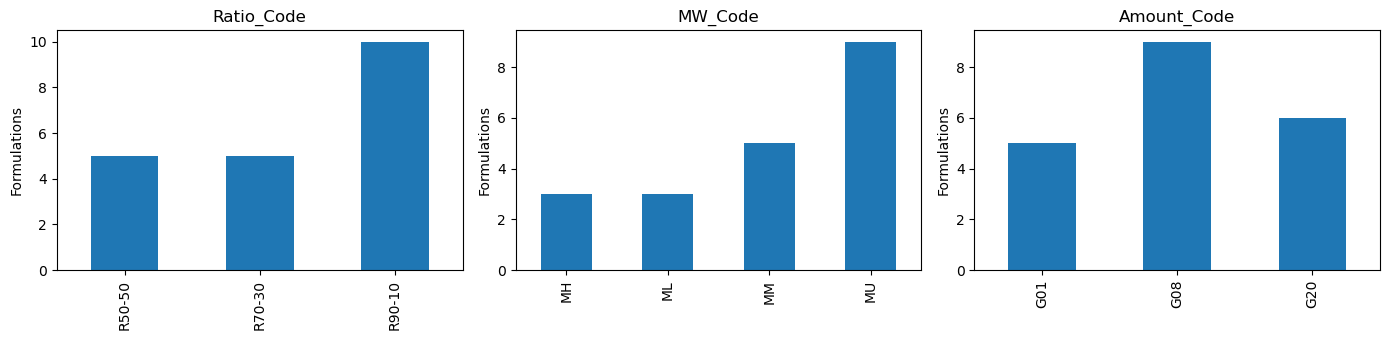

In [9]:
for (glucan, modification), count in QUOTAS.items():
    observed = ((recommended["Glucan_Code"] == glucan) &
                (recommended["Modification_Code"] == modification)).sum()
    assert observed == count

summary_cols = ["Glucan_Code", "Modification_Code", "Carrier_1_Code",
                "Carrier_2_Code", "Ratio_Code", "MW_Code", "Amount_Code"]
for column in summary_cols:
    print(f"\n{column}")
    display(selected[column].value_counts().rename_axis(column).to_frame("Count"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["Ratio_Code", "MW_Code", "Amount_Code"]):
    selected[col].value_counts().sort_index().plot.bar(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Formulations")
plt.tight_layout()
plt.show()


# 6. Export Results

Save the selected IDs, their original `Dataset.xlsx` rows, a candidate snapshot, and the random-sampling settings.


In [10]:
output_dir = OUTPUT_ROOT / f"generation_{GENERATION:02d}_seed_{SEED}"
if output_dir.exists():
    raise FileExistsError(f"Output exists: {output_dir}. Archive it or change SEED.")
output_dir.mkdir(parents=True)

selected.to_csv(output_dir / "generation_01_selection.csv", index=False)
candidates.to_csv(output_dir / "candidate_snapshot.csv", index=False)

selected_rows = selected[["ID", "Generation", "Selection_Type"]].merge(
    excel, on="ID", how="left", validate="one_to_one"
)
selected_rows.to_excel(output_dir / "generation_01_experiment_sheet.xlsx", index=False)

config = {
    "generation": GENERATION,
    "seed": SEED,
    "mandatory_ids": mandatory_ids,
    "recommended_quotas": {f"{g}-{m}": v for (g, m), v in QUOTAS.items()},
    "xlsx_source": str(xlsx_path),
    "worksheet": SHEET_NAME,
    "selection_method": "quota-constrained random sampling",
    "n_selected": len(selected)
}
with open(output_dir / "selection_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print("Saved to:", output_dir.resolve())


Saved to: C:\Users\洪家賢\NAS\AI code\Nanoparticle-AI-Optimization\notebooks\results\generation_01_seed_42


# Research Notes

The selected formulations are initial experimental candidates, not model-predicted optimal formulations. The original IDs and measured-property columns are retained from `Dataset.xlsx` for subsequent experimental updates.
